# Lab 04-03 · Gauss's Law

Companion to chapter [04-03](../../chapters/04-03-gauss-law.md). Handout: [README.md](README.md).

Gauss's law is a consequence of Coulomb's law, so everything here is computed the hard way, from Coulomb's law and superposition, and compared with the one-line Gauss's-law answers. Cells marked **🔮 Predict** ask for a prediction *before* running. Random numbers use seed 2026.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
q_e, eps0 = 1.602176634e-19, 8.8541878188e-12
ke = 1 / (4 * math.pi * eps0)
rng = np.random.default_rng(2026)

def cube_flux(q, src, half=0.5, n=400, power=2.0):
    # outward flux through the cube [-half, half]^3 by the midpoint rule on each face
    u = -half + (np.arange(n) + 0.5) * 2 * half / n
    A, B = np.meshgrid(u, u)
    dA = (2 * half / n) ** 2
    total = 0.0
    for axis in range(3):
        o = [i for i in range(3) if i != axis]
        for sign in (-1, 1):
            P = np.zeros((3,) + A.shape)
            P[axis] = sign * half; P[o[0]] = A; P[o[1]] = B
            d = P - np.asarray(src, float).reshape(3, 1, 1)
            r = np.sqrt((d**2).sum(axis=0))
            total += (sign * ke * q * d[axis] / r ** (power + 1)).sum() * dA
    return total

## Part 1 — Flux by brute force

Integrate $\vec E\cdot\hat n$ over the six faces of a 1 m cube for a 1 nC charge at (0.2, 0.1, −0.3) m (inside) and at (0.6, 0, 0) m (outside, 10 cm beyond one face).

**🔮 Predict:** both fluxes, in V·m.

In [2]:
print(f"q/eps0           = {1e-9/eps0:.4f} V·m")
print(f"charge inside    : {cube_flux(1e-9, (0.2, 0.1, -0.3)):.4f} V·m")
print(f"charge outside   : {cube_flux(1e-9, (0.6, 0.0, 0.0)):.2e} V·m")

q/eps0           = 112.9409 V·m
charge inside    : 112.9411 V·m
charge outside   : -9.84e-06 V·m


The inside charge gives $q/\varepsilon_0$ to the precision of the grid, wherever it sits; the outside charge gives zero even though the field on the near face is strong. The lines that enter the near face all leave through the others.

## Part 2 — Breaking the inverse square

Pretend the field fell as $1/r^{2+\delta}$ and compute the flux through concentric spheres of growing radius.

**🔮 Predict:** for δ = 0.05, the flux through a 3 m sphere as a fraction of that through a 1 m sphere.

delta = 0.05: flux(3 m)/flux(1 m) = 0.9466


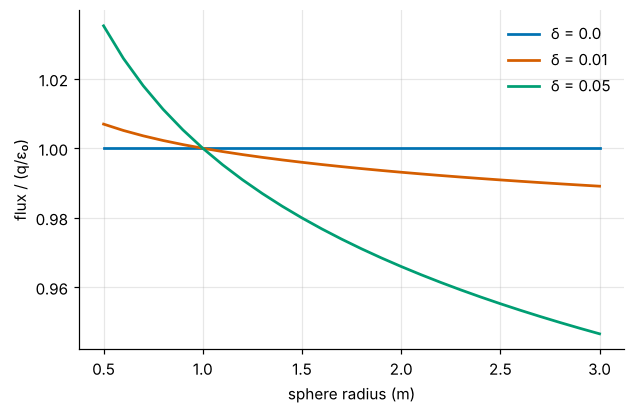

In [3]:
def sphere_flux(q, r, delta):
    th = np.linspace(0, math.pi, 20001)
    return np.trapezoid(ke * q / r ** (2 + delta) * 2 * math.pi * r**2 * np.sin(th), th)
radii = np.linspace(0.5, 3, 26)
for delta in (0.0, 0.01, 0.05):
    phi = [sphere_flux(1e-9, r, delta) for r in radii]
    plt.plot(radii, np.array(phi) / (1e-9 / eps0), label=f"δ = {delta}")
print(f"delta = 0.05: flux(3 m)/flux(1 m) = {sphere_flux(1e-9, 3, 0.05)/sphere_flux(1e-9, 1, 0.05):.4f}")
plt.xlabel("sphere radius (m)"); plt.ylabel("flux / (q/ε₀)"); plt.legend(); plt.show()

Only δ = 0 gives a flux independent of the surface: Gauss's law is the inverse-square law in disguise. The experimental bound on δ is parts in $10^{16}$ (chapter §3.2).

## Part 3 — Gauss's law from superposition

Scatter 20,000 equal point charges, 10 nC in total, uniformly through a sphere of radius 5 cm (Example 04-03.3), add their Coulomb fields directly, and compare with Gauss's law: $k_eQr/R^3$ inside, $k_eQ/r^2$ outside.

**🔮 Predict:** where will the brute-force sum be noisiest?

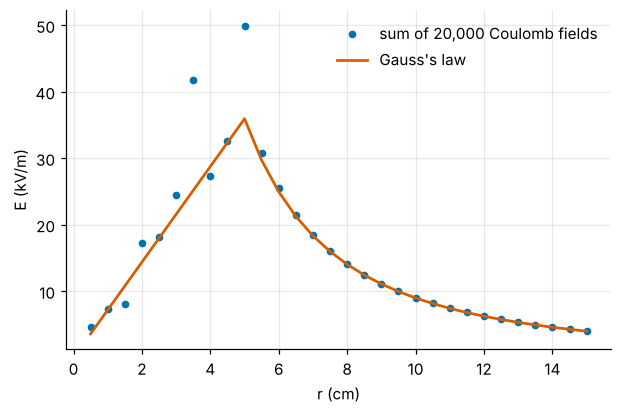

at r = 10.0 cm: sum 9004.8 V/m, Gauss 8987.6 V/m


In [4]:
N, Q, R = 20000, 1e-8, 0.05
pts = rng.normal(size=(N, 3)); pts /= np.linalg.norm(pts, axis=1)[:, None]
pts *= R * rng.random(N)[:, None] ** (1 / 3)           # uniform in volume
r_obs = np.linspace(0.005, 0.15, 30)
E_sum = []
for r in r_obs:
    d = np.array([r, 0, 0]) - pts
    E_sum.append((ke * (Q / N) * d[:, 0] / np.linalg.norm(d, axis=1) ** 3).sum())
E_gauss = np.where(r_obs < R, ke * Q * r_obs / R**3, ke * Q / r_obs**2)
plt.plot(r_obs * 100, np.array(E_sum) / 1e3, "o", ms=4, label="sum of 20,000 Coulomb fields")
plt.plot(r_obs * 100, E_gauss / 1e3, label="Gauss's law")
plt.xlabel("r (cm)"); plt.ylabel("E (kV/m)"); plt.legend(); plt.show()
i10 = np.argmin(abs(r_obs - 0.10))
print(f"at r = {r_obs[i10]*100:.1f} cm: sum {E_sum[i10]:.1f} V/m, Gauss {E_gauss[i10]:.1f} V/m")

Outside, the sum matches $k_eQ/r^2$ closely: far charges average smoothly. Inside, the nearest few random charges dominate and the sum scatters around the straight line. Gauss's law gives the field of the *smoothed* distribution, which is what matters when there are $10^{10}$ charges rather than $2\times10^4$.

## Part 4 — Charges flee to the surface

Release 60 equal charges at random inside a conducting sphere (radius 1, arbitrary units), let each move a small step along the Coulomb force from the others, and keep them inside the sphere.

**🔮 Predict:** where do they end up?

In [5]:
M = 60
x = rng.normal(size=(M, 3)); x *= 0.5 * rng.random(M)[:, None] ** (1/3) / np.linalg.norm(x, axis=1)[:, None]
for step in range(3000):
    d = x[:, None, :] - x[None, :, :]
    r3 = np.linalg.norm(d, axis=2) ** 3 + np.eye(M)
    F = (d / r3[:, :, None]).sum(axis=1)
    x += 5e-3 * F / np.linalg.norm(F, axis=1)[:, None]      # each charge steps 0.005 along its own force
    rr = np.linalg.norm(x, axis=1)
    x[rr > 1] /= rr[rr > 1, None]
rad = np.linalg.norm(x, axis=1)
print(f"charges within 1% of the surface: {np.sum(rad > 0.99)} of {M}; smallest radius {rad.min():.4f}")

charges within 1% of the surface: 60 of 60; smallest radius 1.0000


All of them end on the surface: any charge left inside would feel a net push outward. This is property 2 of chapter §3.4, emerging from nothing but Coulomb repulsion. (The final arrangement on the sphere is the "Thomson problem", a classic puzzle in its own right.)

## Part 5 — Junction fields and touch pads

Gauss's law in one dimension says $\varepsilon_s E(x) = \int\rho\,dx$, so the field is the running integral of the charge. That works for any doping profile.

**🔮 Predict:** for a linearly graded junction, $\rho = qax$ over a width $W$, is the field a triangle?

abrupt: peak 46.40 kV/cm; graded: peak 48.33 kV/cm (q a W^2/(8 eps) = 48.33)


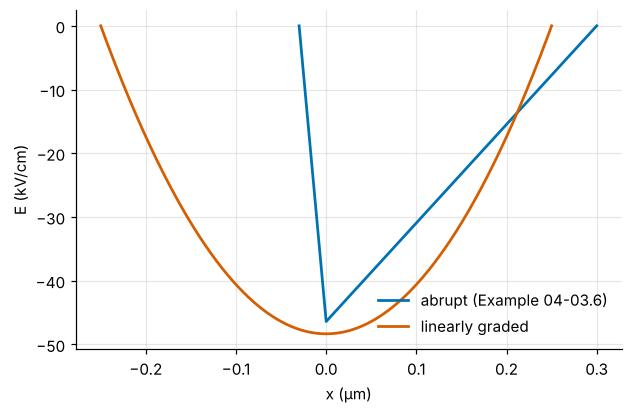

In [6]:
eps_s = 11.7 * eps0
def field_from_rho(x, rho):
    return cumulative_trapezoid(rho, x, initial=0) / eps_s
# abrupt junction of Example 04-03.6
NA, ND, xn = 1e23, 1e22, 0.3e-6; xp = ND * xn / NA
x1 = np.linspace(-xp, xn, 330001)
E1 = field_from_rho(x1, np.where(x1 < 0, -q_e * NA, q_e * ND))
# linearly graded junction: a = 1e21 cm^-4 = 1e29 m^-4, W = 0.5 um
a, W = 1e29, 0.5e-6
x2 = np.linspace(-W / 2, W / 2, 20001)
E2 = field_from_rho(x2, q_e * a * x2)
print(f"abrupt: peak {abs(E1).max()/1e5:.2f} kV/cm; graded: peak {abs(E2).max()/1e5:.2f} kV/cm (q a W^2/(8 eps) = {q_e*a*W**2/(8*eps_s)/1e5:.2f})")
plt.plot(x1 * 1e6, E1 / 1e5, label="abrupt (Example 04-03.6)")
plt.plot(x2 * 1e6, E2 / 1e5, label="linearly graded")
plt.xlabel("x (µm)"); plt.ylabel("E (kV/cm)"); plt.legend(); plt.show()

A graded junction's field is a parabola, not a triangle: the charge density grows toward the edges, so the field's slope does too.

Now the touch pad of Example 04-03.7: a 9 mm fingertip modeled as a parallel plate over a 33 pF pad.

**🔮 Predict:** the finger capacitance through 1 mm of plastic ($\varepsilon_r$ = 3).

C_F through 1 mm of plastic: 1.690 pF


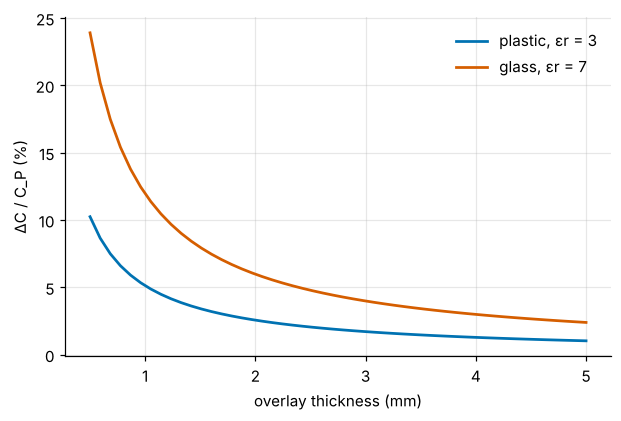

In [7]:
A = math.pi * 4.5e-3**2
d = np.linspace(0.5e-3, 5e-3, 50)
for er, name in ((3, "plastic, εr = 3"), (7, "glass, εr = 7")):
    plt.plot(d * 1e3, er * eps0 * A / d / 33e-12 * 100, label=name)
print(f"C_F through 1 mm of plastic: {3*eps0*A/1e-3*1e12:.3f} pF")
plt.xlabel("overlay thickness (mm)"); plt.ylabel("ΔC / C_P (%)"); plt.legend(); plt.show()

The signal falls as $1/d$, so doubling the overlay halves it; switching plastic for glass recovers more than a factor of two. Real fingers give several times less than this parallel-plate bound (chapter §4, Example 04-03.7).

## Your turn

1. In Part 1, move the outside charge to 1 cm from the face. How fine must the grid be to keep the computed flux below 0.01 V·m? Why does it get harder?
2. In Part 3, increase N to 200,000. How does the scatter inside the sphere change, and why roughly as $1/\sqrt N$?